# Assignment 2: Exploring sources of bias in data
## Bias in data, demystified

**All datasets have limitations. Any of these limitations can be a potential source of bias.** In the context of data, a "bias" is really just a divergence between what a dataset is supposed to capture about the world--according to the *dataset designer's intention*, or according to the *end-user's expectations*--and what's actually represented in the data. 

So biases in data are often highly *contextual*, which can make them subtle and hard to spot. Similarly, it's hard to predict ahead of time what the *consequences* of those biases might be, because it depends on what the data is being used for.

Nevertheless some sources of "bias" in data show up over and over again. Some of these are:
- **duplicated data:** the same data shows up multiple times
- **incomplete data:** some data is missing from the dataset
- **misleading data:** it looks like a piece of data means one thing, but it actually means something different
- **unrepresentative data:** the dataset doesn't represent the population it's gathered from OR the population it's intended to model


Any of these sources of bias, unless their properly documented (with a data statement, etc) can have unintended consequences: they cause a researcher who is using the data to reach incorrect conclusions, or cause a machine learning model that is trained on that dataset to make classification errors.

The nature or scale of these consequences can be hard to predict. That's why any time you prepare to use data that you didn't gather yourself, it pays to spend some time exploring the dataset, identifying limitations, and thinking critically about how these limitations might affect your analysis or your machine learning model.

## Introduction to Assignment 2
For this assignment, you'll be working with the Wikipedia Talk Corpus. You have already created a data statement for this dataset in class, so you're an 'expert' on it compared to most people!

**In assignment 1, you learned how to process and analyze a dataset created by someone else.** In that assignment, we took the dataset at face value: we assumed that there were no major errors, no missing data, nothing that would skew our results. We assumed that the dataset really did accurately capture all the bike and pedestrian traffic on the Burke-Gilman trail over the specified period of time.

**In assignment 2, we'll also be analyzing a dataset created by someone else,** but this time *we won't assume that the data is complete and correct.* Instead, we will try to identify ways in which the data might be WRONG, and form hypotheses about how the limitations we discover might make it an unsuitable, or at least a potentially problematic, training dataset for a general-purpose hostile speech detector. 

**There are 16 questions in this assignment, across three sections:**

***In part 1 of this assignment,*** you will load one type of Wikipedia Talk Corpus data--the demographics of the crowdworkers who labelled the comments--into your copy of this Jupyter Notebook, and we will walk through a series of data processing steps, with the goal of ending up with a complete and accurate set of data about all of those crowdworkers. In the process, we will discover and discuss several limitations of the dataset.

***In part 2 of this assignment,*** you will generate some basic descriptive statistics about the demographics of the crowdworkers described in that dataset. If you are comfortable in Python, you can perform that analysis in this Notebook. If you aren't as comfortable in Python (yet!), you can perform the analysis in Google Sheets (just be sure to link to that Google Sheet from this notebook, and set the permissions so that your instructors can view it!). 

***In part 3 of this assignment,*** you will answer some additional research questions about this dataset. Some of these questions can be answered without writing additional code or analyzing additional data; other questions will require you to combine this dataset another dataset in the corpus. You will have the option to choose whether you want to answer code or no-code questions.

Whether you choose code or no-code question for part 3, you will need to write your responses to the question within this notebook, and submit a link to this notebook for grading.

Part 3 also contains some optional "challenge" questions that you can investigate if you want to (hint: any one of these challenge questions could be the focus of a final course project).


***Note:*** *Since the purpose of this class is to get you comfortable thinking critically (like a researcher), rather than programming perfectly, you won't be graded on your code. You'll be graded on how well you DOCUMENT YOUR PROCESS and REFLECT on the implications of your findings. If you still aren't sure what that means, ask your instructor or TA!*

## Part 1: Cleaning and analyzing the annotator demographic data

For the first part of this assignment, we're going to prepare one set of Wikipedia Talk data--the annotator demographics files--for analysis. In the process we'll perform a few "sanity checks" to make sure we understand what the data means, and know any limitations.

This sort of "[data wrangling](https://en.wikipedia.org/wiki/Data_wrangling)" is a critical, if sometimes tedious, first step for any quantitative research project.

### 1.1 Load the data into the notebook

According to the documetation, the worker demographic data for the Wikipedia Talk Corpus is spread across three files:
- ``toxicity_worker_demographics.tsv``
- ``aggression_worker_demographics.tsv``
- ``attack_worker_demographics.tsv``

We will need to combine the data in these three files to come up with our canonical list of workers. 
**Just like working with data in the real world, you will need to retrieve the files from their source (Figshare) and transfer them into your notebook server**.

- **Toxicity dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Toxicity/4563973) (Note: this is 35Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Toxicity), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png)
- **Aggression dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Aggression/4267550) (Note: this is 74Mb!), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Aggression), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/aggression_question.png)
- **Personal attacks dataset:** [data](https://figshare.com/articles/dataset/Wikipedia_Talk_Labels_Personal_Attacks/4054689) (this is only 92k), [documentation](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Personal_Attacksv), [questionnaire shown to crowdworkers](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/attack_question.png)

First we'll load each of the annotator datafiles into our Notebook and save them into data structures that's easy to work with. In this case, I'm choosing to save each of these files as a list-of-dictionaries, since that's fairly standard, and it makes it easy to check your work as you go.

By the way: ``.tsv`` stands for "tab-separated values", and it means that this file is organized into rows and columns, like a spreadsheet, and the data values for each column are separated by "tab" characters.

In [1]:
#import the csv module, a little code toolkit for working with spreadsheet-style data files
import csv

The function below will load in a tab-separated (.tsv) file and convert it into a lists-of-dictionaries. 

If you don't have much experience with Python, this (and some of the other code in this notebook) might be hard to understand. That's okay! For now, it's most important that you know what it does.

If you have a ***lot*** of experience with Python, the code in this notebook might seem really, really primitive. That's also okay! Remember: in this course we're primarily interested in data, not code. Code is just one of the many tools we use to ask and answer questions about data.

In [2]:
def prepare_datasets(file_path):
    """ 
    Accepts: path to a tab-separated plaintext file
    Returns: a list containing a dictionary for every row in the file, 
        with the file column headers as keys
    """
    
    with open(file_path) as infile:
        reader = csv.DictReader(infile, delimiter='\t')
        list_of_dicts = [dict(r) for r in reader]
        
    return list_of_dicts

### 1.2 Identifying duplicated datafiles
Let's load our three .tsv files into Python and store them as three variables with relevant names, so that we know which is which. 

Once we've created these three lists-of-dicts, we will do two things to check our work so far: 
- we will print the first annotator's demographic data (list index ``[0]``) so that we know what the format looks like
- we will print the length of each list (the ``len`` function), to see how many rows is in each file. Each row should correspond to one crowdworker/annotator.

***Note:*** for the cell below to run, your version of these datafiles and folders will need have the same names as the ones below, and your version of this Notebook will need to be stored in the same directory as the three folders that hold the datafiles.

In [3]:
#load the data from the flat files into three lists-of-dictionaries
toxicity_annotators = prepare_datasets("wikipedia_datasets/toxicity_worker_demographics.tsv")
print(toxicity_annotators[0])
print(len(toxicity_annotators))

attack_annotators = prepare_datasets("wikipedia_datasets/attack_worker_demographics.tsv")
print(attack_annotators[0])
print(len(attack_annotators))

aggression_annotators = prepare_datasets("wikipedia_datasets/aggression_worker_demographics.tsv")
print(aggression_annotators[0])
print(len(aggression_annotators))



{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors'}
3591
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors'}
2190


Interesting! This tells us a few things that we didn't know before:
1. it looks like the demographic data matches what's listed in [the schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv), which is great!
2. it looks like the "toxicity" dataset was annotated by a lot more people (3,591) than the "attack" or "aggression" datasets (2,190)
3. ``aggression_worker_demographics.tsv`` and ``attack_worker_demographics.tsv`` seem to contain the same number of workers, and the worker at the beginning of each list has the same ID and demographic data.

Let's dig a little deeper into finding #3. Are the ***last*** entries in both of these lists also identical?

In [4]:
print(attack_annotators[-1]) # "-1" tells Python to find the last item in any list
print(aggression_annotators[-1])


{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '3876', 'gender': 'female', 'english_first_language': '1', 'age_group': '30-45', 'education': 'bachelors'}


Yes, the last rows in these two lists are also identical! 

And in fact if you had opened the two lists in a text editor or spreadsheet program, you would find that the *aggression and attack .tsv files contain exactly the same data.* By the way, it doesn't say anywhere in the dataset documentation that these two files are identical!

That brings us to our first lesson about bias: watch out for duplicate data! 

Consider: *What would have happened if we had just combined these three files and then analyzed the worker demographics? What mistaken conclusions might we have drawn from that?*
 
Fortunately, now that we know that there is duplicate data we can work around it. Since two files are identical, we only need to use one of them. So from now on, we will ignore ``aggression_annotators`` entirely. 

Since want to remember that ``attack_annotators`` really refers to both "attack" and "aggression" annotators, we can just rename the variable we're using to store that dataset.

In [5]:
attack_aggro_annotators = attack_annotators

Okay, that looks good. Now we can continue getting our data ready for analysis--while keeping an eye out for additional duplicate data and other "gotchas"!

### 1.3 Understanding what the properties of your data really mean

Whenever you are working with data that you didn't create, it's very useful to perform some basic sanity-checking to make sure the data actually means what you think it means. 

For example, take the ``worker_id`` field in our datasets. 

The [schema](https://meta.wikimedia.org/wiki/Research:Detox/Data_Release#Schema_for_{attack/aggression/toxicity}_worker_demographics.tsv) says that the ``worker_id`` field contains an "anonymized crowd-worker id" and that this ID is meant to join the worker demographics datafiles with the annotator comments datafiles, so that if we wanted find all of the comments that worker "85" (from above) labelled, we could find her by looking for that ID in each row of ``toxicity_annotated_comments.tsv``.

So far, so good. But since we want to combine the toxicity and attack + aggression annotator demographics data into a single dataset, we probably want to know...

1. did any of the values for ``worker_id`` appear in both datasets?
2. if so, do they correspond to the same person (or at least, a person with matching gender, age group, etc.)?

### 1.4 Checking for duplicate worker IDs

If we want to see if worker_id means the same thing across datasets, the first step is to see if any of the same worker_ids exist across the two datasets.

To check this, let's first pull all the worker IDs out of each dataset and combine them into a single list. Then we can check that list to see if it contains any duplicate values. If it does, we know that there is at least 1 value for ``worker_id`` that appears in both datasets.

**Note:** *We're assuming that there are no duplicate values for ``worker_id`` within each dataset. (There aren't, I checked). It's a pretty safe assumption though, because worker_id is intended to be a unique key that links the ``worker_demographics.tsv`` files and the ``annotated_comments.tsv`` datasets. Can you explain why it would be an issue if there were duplicate values for ``worker_id`` within an individual dataset?*

In [6]:
#pull the worker ids out of the individual files
tox_w_ids = [item['worker_id'] for item in toxicity_annotators]
aa_w_ids = [item['worker_id'] for item in attack_aggro_annotators]


#create a new list to hold all the ids
all_w_ids = tox_w_ids + aa_w_ids

# #combine the two worker_id lists into the new list
# all_w_ids.extend(tox_w_ids)
# all_w_ids.extend(aa_w_ids)

In [7]:
#how many worker ids do we have, total? 
#this number should match the total count of toxicity_annotators and attack_aggro_annotators (3591 + 2190 = 5781)
print(len(all_w_ids))

5781


In [8]:
#what does our new list look like? Let's print the first five values
print(all_w_ids[0:5])

['85', '1617', '1394', '311', '1980']


Below is our duplicate-checker function. You pass it a list of values, and it will return "True" if it finds at least 1 duplicate value in that list. Can you figure out how it works?

In [9]:
def determine_dupes(w_ids):
    set_of_ids = set()
    
    found_a_dupe = False
    
    for w in w_ids:
        if w in set_of_ids:
            found_a_dupe = True
        else:
            set_of_ids.add(w)

    return found_a_dupe

In [10]:
#we'll call determine_dupes to check for duplicates in the combined worker id list
has_dupes = determine_dupes(all_w_ids)

#if this prints 'True', that means we found at least one duplicate ID
print(has_dupes)

True


Hmmm... So it looks like there's at least 1 duplicate! Okay, we'll need to do some additional verification before we can decide what to do with that information. 

The next thing we'll do is check how many duplicates there are. We'll write a short script that reads through ``all_w_ids`` and every time it finds a value that appears more than once, it adds that value to a new list.

Can you figure out how the script below works?

In [11]:
#create an empty list to hold any duplicate worker_id values we find
dupes = []

#look through the data, if you encounter any value more than once, add it to our 'dupes' list
for w in all_w_ids:
    if all_w_ids.count(w) > 1:
        dupes.append(w)

#how many values were added to 'dupes'?        
print(len(dupes))

#how many worker_ids are present twice in the dataset?
#can you explain why we are dividing the length of "dupes" by 2 in order to answer that question?
print(len(dupes)/2)

3716
1858.0


Huh, so it looks like 1,858 of the ``worker_ids`` in our merged dataset are duplicates! That's a lot of duplication, since our list was only 5,781 rows in the first place, including these dupes! 

We will definitely need to account for these duplicates before we start analyzing worker demographics. 
- If the duplicate ``worker_id``s have different demographic metadata, we will assume they are different people with the same ID. 
- If the metadata is identical, then we know we can safely remove the duplicates
- If some metadata is identical and some is different... well, let's hope that's not the case!

### 1.5 Check for duplicate worker demographic metadata
Let's see if it's just the value for ``worker_id`` that is duplicated across the two datasets (meaning that the these duplicate ids correspond to different workers with different demographics), or if ``worker_id`` really corresponds to the same people across ``toxicity_annotators`` and ``attack_annotators``.

To do this we'll perform some spot checks, meaning we'll visually compare the demographic data of workers with duplicate IDs, to see if they look like the same worker, or not. Running random 'spot checks' is a really common and useful way of finding systematic issues with your data without having to check every entry. 
 

First, we'll extract 10 random ids from our dupe set. Using a random sample (rather than just looking at the first 10 rows, for instance) helps us be more confident that any patterns we see are really there.

In [12]:
#handy Python library that lets you select things randomly from a list
import random

In [13]:
#convert our 'dupes' list into a set
#bonus: can you explain why we created "dupeset" rather than just grabbing 10 random values from "dupes"?
#hint: in Python, a 'set' is like a list that can only contain a single instance of any value
dupeset = set(dupes)

#store our random sample of dupes in its own list
dupe_sample = random.sample(sorted(dupeset), 10)  

#print to confirm everything looks how we expect it to...
print(dupe_sample)

['875', '1533', '3253', '3028', '2745', '1858', '1362', '1637', '3036', '626']


Now, we'll use this ``dupe_sample`` list that we created to pull the corresponding worker demographics from each of our two datasets, using the function below. See if you can figure out how the function works!

In [14]:
def worker_id_lookup(annotator_list, dupe_id):
    """
    Accepts: a list of dictionaries 
        & a list of known duplicate values for
        the key 'worker_id' in those dictionaries
    
    If a duplicate value for worker_id is found, 
        print the complete dictionary of demographic data for that worker
    
    """
    
    for a in annotator_list:
        if a['worker_id'] == dupe_id:
            print(a)
            
#loop through the duplicate sample list and call our worker_id_lookup function
#to check each dataset for corresponding worker demographic data
for d in dupe_sample:
    worker_id_lookup(toxicity_annotators, d)
    worker_id_lookup(attack_aggro_annotators, d)

{'worker_id': '875', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'professional'}
{'worker_id': '875', 'gender': 'female', 'english_first_language': '0', 'age_group': '30-45', 'education': 'bachelors'}
{'worker_id': '1533', 'gender': 'male', 'english_first_language': '0', 'age_group': '18-30', 'education': 'professional'}
{'worker_id': '1533', 'gender': 'male', 'english_first_language': '0', 'age_group': '45-60', 'education': 'masters'}
{'worker_id': '3253', 'gender': 'female', 'english_first_language': '0', 'age_group': '', 'education': 'masters'}
{'worker_id': '3253', 'gender': 'female', 'english_first_language': '0', 'age_group': '30-45', 'education': 'hs'}
{'worker_id': '3028', 'gender': 'male', 'english_first_language': '0', 'age_group': '30-45', 'education': 'hs'}
{'worker_id': '3028', 'gender': 'male', 'english_first_language': '0', 'age_group': '30-45', 'education': 'masters'}
{'worker_id': '2745', 'gender': 'male', 'english_first_language

Aha! It looks like few if any of these ``worker_id`` values correspond to the same demographic data info across the two datasets. 

It's possible that some of the same people labelled both datasets and were assigned different IDs each time. But there's no way for us to determine that with the data we have. 

So for now we will assume that these datasets were labelled by two entirely different sets of crowdworkers. Which means we can combine these two datasets into one, with no duplication to mess up our analysis.

### 1.6 Final preparation of the dataset

Before we start our analysis of worker demographics, let's do two more things:

1. Since we know now that worker ID isn't unique, let's give each worker in our new, combined dataset a **truly** unique ID.
2. While we're at it, let's also add a new field to each worker's demographic dictionary that lists which dataset the worker worked on (toxicity or attack/aggressive).

In [15]:
def add_dataset_id(list_of_dicts, dataset_ref):
    """
    Accepts: a list of dictionaries & a strig value for "dataset"
    Returns: that list of dictionaries, with the new "dataset" key and the specified value
    """
        
    for w in list_of_dicts:
        w.update({"dataset" : dataset_ref})
        
    return list_of_dicts

In [16]:
#update our worker demographic datasets with the new key and value
toxicity_annotators = add_dataset_id(toxicity_annotators, "toxicity")
attack_aggro_annotators = add_dataset_id(attack_aggro_annotators, "attack and aggression")

In [17]:
#did it work?
print(toxicity_annotators[0])
print(attack_aggro_annotators[0])

{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity'}
{'worker_id': '833', 'gender': 'female', 'english_first_language': '0', 'age_group': '45-60', 'education': 'bachelors', 'dataset': 'attack and aggression'}


Great. Now we'll use the function below to... 

1. combine the two datasets into one
2. assign a truly unique id to each worker 

It doesn't matter what this ID is, as long as its unique within the dataset. We'll use sequential IDs, starting at "1" and going up from there.

In [18]:
def finalize_dataset(list1, list2):
    
    #combine the two lists into a new one
    combined_list = list1 + list2
    
    #initialize our counter variable
    new_id = 1
    
    for w in combined_list:
        #add the new sequential id field, and populate with the current value of 'counter'
        w.update({"unique_id" : str(new_id)})
        
        #increment the counter variable by 1, so that the next ID will be one number higher
        new_id = new_id + 1
        
    return combined_list

In [19]:
#create our new combined list with sequential IDs
all_annotators = finalize_dataset(toxicity_annotators, attack_aggro_annotators)

#print the list length and a sample, for sanity-checking purposes
print(len(all_annotators))
print(all_annotators[0])

5781
{'worker_id': '85', 'gender': 'female', 'english_first_language': '0', 'age_group': '18-30', 'education': 'bachelors', 'dataset': 'toxicity', 'unique_id': '1'}


It worked! Now we can FINALLY start to analyze this dataset, and find out more about the workers who labelled the Wikipedia Talk Corpus.

## Part 2: Analyzing worker demographics

Now that we have our worker demographic data de-duplicated, combined and uniquely identified, we can start using it to ask and answer research questions! 

You are welcome to do this next steps in Python, here in this notebook. But if you aren't super comfortable with Python, you can run the cell below to export this dataset to a .csv file called ``a2_all_annotator_demographics.csv`` which you can open in Google Sheets and do the analysis there.

Note: if you choose Google Sheets, please title your Google Sheet "A2 worker demographics", share it with your instructor and TA ("can view" or "can edit") and paste a link to it in a Markdown cell below.

In [20]:
with open('a2_all_annotator_demographics.csv', 'w', encoding='utf-8') as f:
    writer = csv.writer(f)
    #write a header row
    writer.writerow(('unique_id',
                     'worker_id', 
                     'gender', 
                     'english_first_language', 
                     'age_group',
                     'education',
                     'dataset',))
    #loop through our dataset and write it to the file, row by row
    for a in all_annotators:
        writer.writerow((a['unique_id'], a['worker_id'], a['gender'], a['english_first_language'], a['age_group'], a['education'], a['dataset']))

### 2.1 Questions 1-4: compute descriptive statistics

Please create tables or bar charts that answer the following questions:

- **Q1.** What is the gender distribution of these workers?
- **Q2.** What is the distribution of the workers by first language?
- **Q3.** What is the distribution of these workers by age group?
- **Q4.** what is the distribution of these workers by education level?

If you *do not know* how to create tables in Python, you can use Excel or another tool and upload it to your notebook server. However I would encourage you to try out the [Pandas](https://pandas.pydata.org/pandas-docs/version/0.15/10min.html) library, which makes it very easy to convert your data into tidy tabular representations. If you do not know how to create charts in Python, you can use an easy library such as [Plotly](https://plotly.com/python/v3/statistics-charts/#new-to-plotly) to create charts.

**POST YOUR ANSWERS TO QUESTIONS 1-4 HERE.**

Use both Markdown and code-formatted cells.

Total workers: 5781


,count,percent
gender,,
male,3676,63.6
female,2103,36.4
other,2,0.0


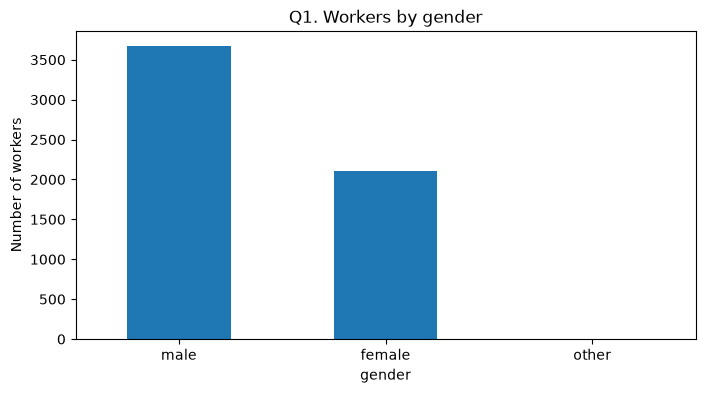

,count,percent
english_first_language,,
0,4713,81.5
1,1068,18.5


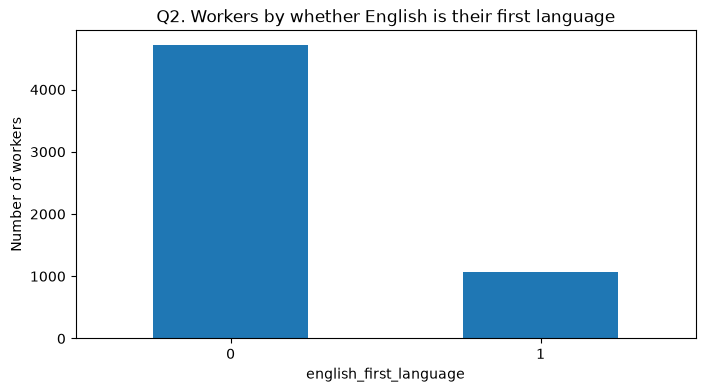

,count,percent
age_group,,
18-30,2911,50.4
30-45,2078,35.9
45-60,514,8.9
Under 18,116,2.0
,112,1.9
Over 60,50,0.9


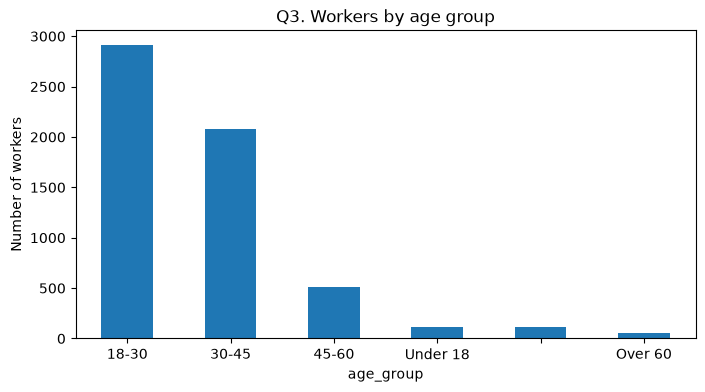

,count,percent
education,,
bachelors,2303,39.8
hs,1657,28.7
masters,931,16.1
professional,684,11.8
some,141,2.4
doctorate,61,1.1
none,4,0.1


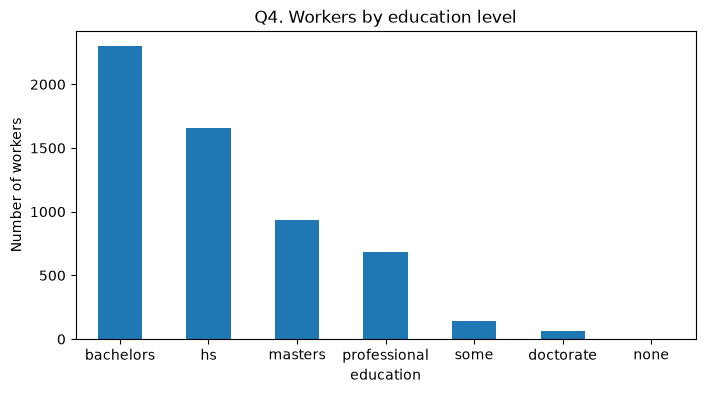

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Turn the combined list of worker dictionaries from Part 1 into a table
workers = pd.DataFrame(all_annotators)
print("Total workers:", len(workers))

# Count and percent of workers in each category, plus a bar chart, for one demographic field
def show_distribution(column, title):
    counts = workers[column].value_counts()
    table = pd.DataFrame({"count": counts, "percent": (counts / len(workers) * 100).round(1)})
    display(table)

    counts.plot(kind="bar", figsize=(8, 4))
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel("Number of workers")
    plt.xticks(rotation=0)
    plt.show()

# Q1: gender
show_distribution("gender", "Q1. Workers by gender")

# Q2: first language (1 = English is first language, 0 = it is not)
show_distribution("english_first_language", "Q2. Workers by whether English is their first language")

# Q3: age group
show_distribution("age_group", "Q3. Workers by age group")

# Q4: education level
show_distribution("education", "Q4. Workers by education level")



## Q1–Q4 answers

**How I did this:** I turned all_annotators (the combined, de-duplicated list from Part 1) into a pandas table with 5,781 rows, one per worker record. For each demographic field, I counted how many workers fall into each category, converted those counts to percentages of all 5,781 workers, and made a bar chart. All percentages below are out of 5,781.

**Q1. Gender:** The workers are mostly male: **3,676 (63.6%)** vs. **2,103 female (36.4%)**. Only 2 workers (less than 0.1%) chose "other." So men outnumber women almost 2 to 1. Because only 2 workers chose "other," the data can't tell us anything meaningful about non-binary workers.

**Q2. First language:** This field is stored as 1 (English is their first language) or 0 (it is not). Only **1,068 workers (18.5%)** have English as their first language, while **4,713 (81.5%)** do not. This was the most surprising result, because every comment these workers labelled was written in English. Judging whether a comment is toxic often depends on slang, sarcasm, and tone, which can be harder to read in a second language.

**Q3. Age group:** The workers skew young. Half are 18–30 (**2,911, 50.4%**), and another 35.9% are 30–45, so **86%** are under 45. Only **50 workers (0.9%)** are over 60. There are also **116 workers (2.0%)** under 18, which is notable since minors were labelling potentially offensive content. Finally, **112 workers (1.9%)** have no age group at all, which shows up as the blank bar in the chart. This is missing data, which I look at in Q5.

**Q4. Education:** The most common level is a bachelor's degree (**2,303, 39.8%**), followed by high school (**1,657, 28.7%**), master's (**931, 16.1%**), and professional (**684, 11.8%**). Only 4 workers (0.1%) reported no education. Some categories are unclear: the dataset doesn't explain what "some" (141 workers) or "professional" means, so I can't be sure how these workers described themselves. That is an example of potentially misleading data.

**What this tells me overall:** The typical worker in this dataset is a man aged 18–45 with at least a bachelor's degree whose first language is not English. These are the people who decided what counts as toxic in English Wikipedia comments, so a model trained on their labels learns their idea of toxicity. One caution: these are worker records, not necessarily unique people. As Part 1 showed, someone who worked on both the toxicity and attack/aggression tasks may appear twice under different IDs, so the true number of people could be lower.


### 2.2 Questions 5-8

Each of the next four questions requires a different kinds of answer.

Questions 5 and 6 have a "correct" answer, but we'll still give you credit for the "incorrect" answer as long as you document your process well (in Markdown, in this notebook). These questions are intended to get you thinking about how even small errors in data processing can create bias in your data.

Question 6 requires you to re-run some (but not all) of the data processing steps you performed above. Do this by copying the code into NEW cells below this line, and make sure to document each step using Markdown cells or inline (#) comments. You will probably want to change the names of the variables too.

- **Q5.** Analyze all_annotators in Sheets or Jupyter: Do any of the fields in this dataset have missing data? If so, which fields, and what % of the rows contain missing values?
- **Q6.** Build a version of the all_annotators dataset *without removing duplicates*, then re-run the summary statistics from questions 1-4. How have these summary statistics changed?

Questions 7 and 8 don't have one "correct" answer. These questions are intended to get you thinking about how using this dataset to train a machine learning model might lead to bias in the way that model performs when used as intended. You will need to provide a written answer to each of these questions in 3-4 full sentences. Consider what you know about the workers themselves, the task they were given, and about the purpose of the Perspective API.

Question 7 requires you to do some research of your own (hint: use Google). Question 8 doesn't require any new analysis or research, just critical thinking.

- **Q7.** In general, how do the demographics of these workers compare to those of English-speaking internet users overall? Why would it matter if the worker demographics don't match the demographics of the intended end users of the Perspective API?

- **Q8.** Given what you now know about the Wikipedia Talk Corpus, what issues might arise if it was used to train a machine learning-driven "hostile speech detector" that could be used on any website or social media platform?


**POST YOUR ANSWERS TO QUESTIONS 5-8 HERE.**

Use both Markdown and code-formatted cells.

In [22]:
# Q5: Count missing values (NaN or empty string) in each field
workers = pd.DataFrame(all_annotators)

for column in ["worker_id", "gender", "english_first_language", "age_group", "education"]:
    missing = (workers[column].isna() | (workers[column].str.strip() == "")).sum()
    print(f"{column}: {missing} missing ({missing / len(workers) * 100:.2f}% of {len(workers)} rows)")

# Workers with no age group, by dataset
no_age = workers[workers["age_group"].str.strip() == ""]
print("\nWorkers with no age group, by dataset:")
print(no_age["dataset"].value_counts())

# Q6: Reload all three files fresh so the Part 1 data isn't changed
dup_toxicity   = prepare_datasets("wikipedia_datasets/toxicity_worker_demographics.tsv")
dup_attack     = prepare_datasets("wikipedia_datasets/attack_worker_demographics.tsv")
dup_aggression = prepare_datasets("wikipedia_datasets/aggression_worker_demographics.tsv")

# Label each worker with its source dataset
dup_toxicity   = add_dataset_id(dup_toxicity, "toxicity")
dup_attack     = add_dataset_id(dup_attack, "attack")
dup_aggression = add_dataset_id(dup_aggression, "aggression")

# Combine all three files, keeping the duplicate aggression file
all_annotators_with_dupes = finalize_dataset(dup_toxicity, dup_attack + dup_aggression)
print("\nRows without duplicates:", len(all_annotators))
print("Rows with duplicates:   ", len(all_annotators_with_dupes))

# Compare Q1–Q4 counts and percentages with and without duplicates
workers_dupes = pd.DataFrame(all_annotators_with_dupes)

for column in ["gender", "english_first_language", "age_group", "education"]:
    clean = workers[column].value_counts()
    dupes = workers_dupes[column].value_counts()
    comparison = pd.DataFrame({
        "count (clean)": clean,
        "% (clean)": (clean / len(workers) * 100).round(1),
        "count (with dupes)": dupes,
        "% (with dupes)": (dupes / len(workers_dupes) * 100).round(1),
    })
    comparison["% change"] = (comparison["% (with dupes)"] - comparison["% (clean)"]).round(1)
    print(f"\n=== {column} ===")
    display(comparison)


worker_id: 0 missing (0.00% of 5781 rows)
gender: 0 missing (0.00% of 5781 rows)
english_first_language: 0 missing (0.00% of 5781 rows)
age_group: 112 missing (1.94% of 5781 rows)
education: 0 missing (0.00% of 5781 rows)

Workers with no age group, by dataset:
dataset
toxicity                 77
attack and aggression    35
Name: count, dtype: int64

Rows without duplicates: 5781
Rows with duplicates:    7971

=== gender ===


,count (clean),% (clean),count (with dupes),% (with dupes),% change
gender,,,,,
male,3676,63.6,5025,63.0,-0.6
female,2103,36.4,2943,36.9,0.5
other,2,0.0,3,0.0,0.0



=== english_first_language ===


,count (clean),% (clean),count (with dupes),% (with dupes),% change
english_first_language,,,,,
0,4713,81.5,6501,81.6,0.1
1,1068,18.5,1470,18.4,-0.1



=== age_group ===


,count (clean),% (clean),count (with dupes),% (with dupes),% change
age_group,,,,,
18-30,2911,50.4,3960,49.7,-0.7
30-45,2078,35.9,2909,36.5,0.6
45-60,514,8.9,732,9.2,0.3
Under 18,116,2.0,153,1.9,-0.1
,112,1.9,147,1.8,-0.1
Over 60,50,0.9,70,0.9,0.0



=== education ===


,count (clean),% (clean),count (with dupes),% (with dupes),% change
education,,,,,
bachelors,2303,39.8,3165,39.7,-0.1
hs,1657,28.7,2288,28.7,0.0
masters,931,16.1,1316,16.5,0.4
professional,684,11.8,927,11.6,-0.2
some,141,2.4,189,2.4,0.0
doctorate,61,1.1,81,1.0,-0.1
none,4,0.1,5,0.1,0.0


## Q5–Q8 answers

**Q5. Missing data**

I counted blank values in every field of all_annotators. A standard missing-value check (NaN) returned zero for every field, because this dataset stores missing values as an empty string ("") instead of a true blank. Someone running only the standard check would wrongly conclude the data is complete, so I counted empty strings as missing too. Only one field has missing data: age_group is missing for **112 of 5,781 workers (1.94%)**. Every other field (worker_id, gender, english_first_language, education) is complete. This means any conclusion about age and toxicity labelling leaves out these workers, and we can't tell whether they skew toward a particular age.

**Q6. Without removing duplicates**

I reloaded all three demographic files, labelled each worker with its source file, and combined all three, including the aggression file that Part 1 showed is an exact copy of the attack file. Then I re-ran the Q1–Q4 breakdowns side by side with the clean version. The dataset grows from **5,781 to 7,971 rows**, which means 2,190 workers are counted twice, a **38%** inflation. However, the percentages barely change. Every category shifts by less than 1 percentage point (for example, male 63.6% to 63.0%, age 18–30 50.4% to 49.7%, English as first language 18.5% to 18.4%). That is what makes this error dangerous: nothing looks wrong in the percentages, but anyone reporting the raw counts would overstate the workforce by 38%. The duplicates also give the attack/aggression workers double the weight of the toxicity workers. Those two groups happen to have similar demographics here, but if they didn't, the same mistake could have quietly skewed the results.

**Q7. Workers vs. English-speaking internet users**

The workers skew much more male and younger than internet users overall: they are **63.6%** male and only **0.9%** are over 60, while internet use is close to equal between men and women worldwide (70% vs. 65%, with full parity in the Americas and Europe) ([ITU, 2024](https://www.itu.int/itu-d/reports/statistics/2024/11/10/ff24-the-gender-digital-divide/)), even though older adults make up a large share of internet users. Also, **81.5%** of workers do not speak English as a first language, unlike many commenters on English Wikipedia and on U.S. and U.K. news sites where the Perspective API is used. This matters because the API learns what "toxic" means from these workers' judgments, so it reflects their sense of what is offensive. It may miss harassment that women or older users find hurtful, or misread slang, sarcasm, and dialects, judging users by standards they did not help set.

**Q8. Using it as a general-purpose hostile speech detector**

The Wikipedia Talk Corpus comes from one narrow setting, editors arguing about encyclopedia edits, while toxicity on gaming sites, dating apps, or social media looks very different. A model trained only on Wikipedia would likely miss kinds of hostility it never saw and wrongly flag harmless language that just looks unusual compared to Wikipedia. Combined with the workers' skewed demographics, it may also be harsher on dialects like African American English or on non-native writers. Because it is marketed as general-purpose, platforms might trust it without testing it on their own users, silencing some groups more than others at a very large scale.


## Part 3: Digging deeper

### 3.1 Questions 9-16

Below is a list of additional questions that you should be able to answer, based on what you've done today. 

***You may answer EITHER the "code" questions (Q9-Q12) OR the "no code" questions (Q13-Q16).***

If you don't feel very comfortable with Python yet, choose the "no code" questions.

- ***For the "code" questions*** you will need to load ``toxicity_annotations.tsv`` into Python and join that dataset with ``all_annotators`` on ``worker_id``.
- ***For the "no code" questions*** you will need to load the file ``toxicity_labelled_comments_3k_sample.csv`` into Google Sheets. This file contains the text of 3000 comments that were annotated for toxicity, as well as the toxicity score that each worker gave to these comments. The file is a random sample taken from the ~1.5 million comments contained in ``toxicity_annotated_comments.tsv``

*Note:* answering question 13-16 below ***will require reading some comments that contain offensive speech!*** If you do not want to be exposed to offensive speech, either answer the "code" questions instead, or reach out to your Instructor or TA and ask for an alternate activity.

#### Code questions
- **Q9.** What % of *workers* who labelled the toxicity dataset do we have demographic data for?
- **Q10.** What % of the *comments* in the toxicity dataset were labelled by male vs. female-identified workers?
- **Q11.** What % of the *comments* in the toxicity dataset were labelled by people for whom English is NOT their first language?
- **Q12.** Based on your findings from questions 9-11, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs? 

#### No-code questions

Before you answer the questions below, read through at least 20 comments from ``toxicity_labelled_comments_3k_sample.csv`` that were labelled "toxic" (-1 or -2), 20 that were labelled "non-toxic" (1 or 2), and 20 that are labelled "neutral" (0). Note in your spreadsheet whether you agree or disagree with the labeller's judgement. 


- **Q13.** Pick 2-3 examples of comments where you disagreed with the labeller about the toxicity of a comment. Why did you disagree? Why do you think that the labeller might have labelled these comments the way they did?
- **Q14.** Pick 2-3 examples of comments where you don't understand what the commenter was saying, and therefore had a hard time classifying as toxic or non-toxic. What additional context or information would you need in order to be confident in your judgement about the toxicity of this comment?
- **Q15.** Read through the [instructions and labelling options](https://github.com/ewulczyn/wiki-detox/blob/master/src/modeling/toxicity_question.png) given to the crowdworkers. How could the way these instructions were written have made it difficult for crowdworkers to accurately label comments as toxic or non-toxic? If you were going to run a labelling campaign like this one yourself, how would you change these instructions or labelling options to help the crowdworkers make more accurate or consistent judgements about toxicity?
- **Q16.** Based on your findings from questions 13-15, how might this dataset present a biased view of "toxicity"? How would you expect such biases to impact how the Perspective API performs as a general-purpose hostile speech detector? 

**POST YOUR ANSWERS TO QUESTIONS 9-16 HERE.**

Use both Markdown and code-formatted cells.

In [23]:
# Load the 3,000-comment sample; each row is one worker's toxicity score for one comment
comments = pd.read_csv("toxicity_labelled_comments_3k_sample.csv")

# Replace the dataset's line-break placeholder with spaces
comments["comment"] = comments["comment"].str.replace("NEWLINE_TOKEN", " ").str.strip()

# Drop repeated comments so the same comment isn't picked twice
comments = comments.drop_duplicates(subset="rev_id")

# Pick 20 random comments from each label group (-2/-1 toxic, 0 neutral, 1/2 non-toxic)
toxic    = comments[comments["toxicity_score"] < 0].sample(20, random_state=1)
neutral  = comments[comments["toxicity_score"] == 0].sample(20, random_state=1)
nontoxic = comments[comments["toxicity_score"] > 0].sample(20, random_state=1)

# Combine all 60 with empty columns for my own judgment and notes
to_review = pd.concat([toxic, neutral, nontoxic])[["rev_id", "toxicity_score", "comment"]]
to_review["agree_with_label"] = ""
to_review["notes"] = ""

# Save the spreadsheet only if it doesn't exist yet, so my filled-in judgments are never overwritten
import os
if not os.path.exists("comments_to_review.csv"):
    to_review.to_csv("comments_to_review.csv", index=False)
    print("Saved", len(to_review), "comments to comments_to_review.csv")
else:
    print("comments_to_review.csv already exists, not overwriting my judgments")

print(to_review["toxicity_score"].value_counts().sort_index())


comments_to_review.csv already exists, not overwriting my judgments
toxicity_score
-2.0     5
-1.0    15
 0.0    20
 1.0    19
 2.0     1
Name: count, dtype: int64


## Q13–Q16 answers (no-code track)

**How I did this:** I used the code above to remove repeated comments (24 of the 3,000 rows were repeats) and then pick 20 random comments labelled toxic (-1 or -2), 20 labelled neutral (0), and 20 labelled non-toxic (1 or 2) from toxicity_labelled_comments_3k_sample.csv. I read each one and recorded in comments_to_review.csv (in this folder) whether I agreed with the label and why. Row numbers below refer to that spreadsheet. Each label in this file is one worker's rating, not the average of all ~10 workers who rated the comment.

I disagreed with **12 of 60** labels (20%). The disagreements went both ways: **7 of the 15** comments labelled toxic (-1) looked civil or merely frustrated to me, while **3** comments containing insults or a slur were labelled neutral or healthy (one of these, row 48, I also discuss in Q14 because its context was unclear).

**Q13. Comments where I disagreed with the labeller**

1. Row 18 (labelled -1, toxic): a user in an argument about the iPod article writes "maybe we should look at articles about the iPod in reliable sources... if it's commonly referred to as iPod then I will cede my point. Acceptable?" This is a civil compromise, so I would label it 0 or 1. The labeller may have reacted to the phrase "aggressively dismissed," which the user is quoting from someone else, or to the slightly sarcastic "I'm not going to get any apologies."
2. Row 21 (labelled -1, toxic): a short correction of German grammar: "God died is Gott ist gestorben." I would label it 0. The labeller may have reacted to the phrase "God died," which could look offensive or blasphemous out of context, even though the comment is purely about translation.
3. Row 34 (labelled 0, neutral): a user calls another editor "a douche," "a prick," and "a dildouche." I would label it -1 or -2. The labeller may have been rushing, or may not have known some of these English slang insults. It's also possible that, since the insults weren't aimed at them, they didn't feel the comment would make them "leave a discussion," which is how the instructions define toxic.

**Q14. Comments I had trouble understanding**

1. Row 11 (labelled -1): "Any response I have will probably get placed on your talk page." On its own, this reads as neutral. But it could be a veiled threat, such as a warning that the user will report someone or post something hostile publicly. To judge it, I would need the earlier messages in the conversation and to know what this user usually posts on other people's talk pages.
2. Row 48 (labelled 1, healthy): this comment has a racial slur in its section heading, but the body asks people not to make personal attacks, and mentions "meatpuppets," vegans, and a user named Vigger. I couldn't tell whether the commenter was using the slur, quoting someone else's term, or reacting to a username. I would need the full discussion thread, an explanation of Wikipedia jargon like "meatpuppet" (a person recruited to support one side of a debate), and who wrote the heading.

**Q15. The labelling instructions**

Workers were asked to "rate the toxicity of this comment" on five options. "Toxic" was defined as "a rude, disrespectful, or unreasonable comment that is somewhat likely to make you leave a discussion," and "Neither" had no definition at all. These instructions make accurate labelling hard in a few ways. First, they rely on how the worker personally feels ("make you leave a discussion"), but the worker isn't in the discussion, so an insult aimed at someone else may not feel toxic to them (row 34). Second, one scale mixes very different things, such as rudeness, hate, and simple unreasonableness, so a frustrated but civil comment (row 18) can end up in the same category as a personal attack. Third, there is no option for "I can't tell without more context," so workers had to guess on comments like rows 11 and 48. Finally, there's no guidance on quoting or discussing an offensive word versus using it against someone (rows 20 and 48).

If I ran this labelling campaign, I would: (1) show the previous comments in the thread, not just one comment; (2) add an "unsure / need more context" option; (3) give concrete definitions with examples for each option, including "Neither"; (4) split toxicity into separate questions (e.g., insult, slur, threat, aimed at a person or not); and (5) explicitly say that quoting or discussing an offensive term is different from using it.

**Q16. How this could bias the dataset and the Perspective API**

Based on my sample, the dataset's idea of "toxic" seems to depend on individual words more than on meaning or intent. Civil comments that happen to contain words like "aggressively" or "God died" were labelled toxic, while comments with casual or less common insults like "prick" or "wanker" (row 61) were labelled neutral or even healthy. This could be related to what we found in Part 2: most workers were not native English speakers, so slang and regional insults may be harder for them to recognize. This sample doesn't show which workers gave which labels, though, so I can't confirm that link. A Perspective API trained on these labels would likely over-flag heated but civil debate and anyone discussing or quoting offensive language, such as people explaining why a term is racist (row 20). At the same time, it could miss everyday insults and veiled threats that need context to understand. As a general-purpose detector, it could end up silencing people who talk about racism and disagreement, while letting real harassment through.


### 3.2 Challenge questions (optional)

The questions below are optional; you don't need to answer them to receive full credit for this assignment.

If you'd like to explore additional analyses of this dataset, here are a few questions to get you started!

- ***Challenge #1.*** Are female-identified workers more likely to label a comment as "toxic" than male identified workers? 
- ***Challenge #2.*** Are workers with a higher level of education more consistent in their "toxicity" labelling--in other words, do they tend to agree with other labellers more often? (remember that, according to the documentation, every comment was labelled by at least 10 crowdworkers). 
- ***Challenge #3.*** What are the words most frequently associated with toxic comments? (perhaps focus on comments where most or all of the workers agree are toxic)
- ***Challenge #4.*** What are the most polarizing comments--comments that some workers consider toxic, and others consider non-toxic? What about these comments made them so polarizing, or hard to classify?
- ***Challenge #5.*** Answer some or all of the homework questions above for one the other datasets ("attack" and "aggressive"). How are the potential sources of bias for these datasets the same, or different, than for the toxicity dataset? Would you "trust" a machine learning model based on these datasets more or less than one trained on the "toxicity" dataset? Why?

*OPTIONAL: POST YOUR ANSWERS TO THE CHALLENGE QUESTIONS HERE.*

Use both Markdown and code-formatted cells.

## Use of AI

I used Claude (in VS Code) as an assistant for coding throughout this assignment.

**What Claude did:**
- Help write the code for Q1–Q4 (tables and charts), Q5 (missing-data check), Q6 (rebuilding the dataset with duplicates), and Part 3 (picking 60 comments to review).
- Found and fixed an error in the provided Part 1 code: random.sample no longer accepts a set in newer Python, so sorted() was added.
- Edited the Part 3 code so re-running it can't overwrite my spreadsheet.